# UAE Flood Response - April 2024 (Dubai-Sharjah-Ajman)

## Part 0 - Setup
**CELL 1: Install the required libraries**

Installs the Python libraries used for geospatial analysis and mapping.

In [ ]:
!pip install geemap rasterio osmnx -q

**CELL 2: Initialise Earth Engine and display the study area**

Authenticates with Google Earth Engine and displays a map of the study area. The rectangle 'roi' defines the region of interest covering Dubai, Sharjah and Ajman.

In [ ]:
import ee, geemap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ID = "asis-504307"
ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

roi = ee.Geometry.Rectangle([55.0, 24.9, 55.6, 25.45])

m = geemap.Map(center=[25.2, 55.3], zoom=9)
m.add_basemap("HYBRID")          # Google satellite + labels, avoids OSM
m.addLayer(roi, {"color": "red"}, "ROI")
m

Map(center=[25.2, 55.3], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

**CELL 2b: Visibility helpers**

Defines the helper functions used by all maps: a dimmed basemap, a glow effect for flood layers, bold point markers and a high-contrast zone colour scheme. The glow and marker enlargement are for display only; all areas are computed on the original masks.

In [ ]:
# ===== VISIBILITY HELPERS: glow, dimmed background, bold markers, high-contrast zone map =====
from matplotlib.colors import ListedColormap

# ---- knobs (change these if things are still too small / too big) ----
GLOW     = 1.0   # interactive maps: 1 = zoom 10-12 | 2-3 = whole-UAE zoom (8-9) | 0.5 = very close
GLOW_PX  = 45    # static figures: how far the glow spreads (raster pixels)
CORE_PX  = 8     # static figures: how much the flood blobs are fattened (raster pixels)

# ---------- Interactive maps (geemap) ----------
def dim_basemap(m, opacity=0.45):
    """Black veil over the satellite so bright layers pop. Call it right after add_basemap().
    Untick 'Dim basemap' in the layers button to remove it."""
    m.addLayer(ee.Image.constant(0), {'min': 0, 'max': 1, 'palette': ['000000']},
               'Dim basemap', True, opacity)

def glow_image(mask, color='FF1744', core='FFFFFF'):
    """Mask -> ONE layer: black shadow + coloured glow rings + white-hot core.
    Radii are in metres and scaled by GLOW. Enlarged for DISPLAY ONLY (areas are still computed on the real mask)."""
    mask = mask.selfMask()
    rings = [(1300, '000000', 0.35),    # dark shadow = black/white contrast
             (900,  color,    0.15),
             (450,  color,    0.28),
             (220,  color,    0.50),
             (100,  color,    0.80)]
    out = None
    for r, col, a in rings:
        lyr = mask.focal_max(r * GLOW, 'circle', 'meters').visualize(palette=[col], opacity=a)
        out = lyr if out is None else out.blend(lyr)
    if core:
        out = out.blend(mask.focal_max(40 * GLOW, 'circle', 'meters').visualize(palette=[core]))
    return out

def bold_points(fc, fill='FFEB3B', size=9, halo=True):
    """Points with a white outline and (optionally) a soft halo, so they stay visible when zoomed out."""
    img = fc.style(color='FFFFFF', fillColor=fill, pointSize=size, width=2)
    if halo:
        ring = fc.style(color='00000000', fillColor=fill + '55', pointSize=size * 3, width=0)
        img = ring.blend(img)
    return img

# ---------- Static figures (matplotlib) ----------
# zone codes: 0 dry, 1 hotspot, 2 shallow, 3 medium, 4 deep, 5 sea
ZONE_COLORS = ['#263238', '#E040FB', '#FFEA00', '#FF9100', '#FF1744', '#0D47A1']
ZONE_LABELS = ['Dry', 'Hotspot (low ground)', 'Flood <0.5 m', 'Flood 0.5-1.5 m', 'Flood >1.5 m', 'Sea / outside UAE']
cmap = ListedColormap(ZONE_COLORS)

def draw_zone_map(ax, zone, ext, cmap):
    """Zone map on a dark background + black shadow + red glow + fattened flood + white outline."""
    from scipy.ndimage import grey_dilation, distance_transform_edt
    h_, w_ = zone.shape
    ax.set_facecolor('black')
    ax.imshow(zone, cmap=cmap, vmin=-0.5, vmax=5.5, extent=ext, interpolation='nearest')
    fl = (zone >= 2) & (zone <= 4)
    if not fl.any():
        return
    d = distance_transform_edt(~fl)                  # distance (pixels) to nearest flood pixel
    def veil(rgb, reach, strength):
        a = np.exp(-d / (reach / 3.0)); a[d > reach] = 0
        img = np.zeros(d.shape + (4,)); img[..., :3] = rgb; img[..., 3] = a * strength
        ax.imshow(img, extent=ext, interpolation='bilinear')
    veil((0, 0, 0), GLOW_PX * 1.6, 0.60)             # dark shadow
    veil((1, 0.09, 0.27), GLOW_PX, 0.90)             # red glow
    big = grey_dilation(np.where(fl, zone, 0), size=(2 * CORE_PX + 1,) * 2)   # fatter flood, deepest zone wins
    ax.imshow(np.ma.masked_less(big, 2), cmap=cmap, vmin=-0.5, vmax=5.5, extent=ext, interpolation='nearest')
    Xc = np.linspace(ext[0], ext[1], w_); Yc = np.linspace(ext[3], ext[2], h_)
    ax.contour(Xc, Yc, (big >= 2).astype(float), levels=[0.5], colors='white', linewidths=0.8)


## Part 1 - Find the satellite images
**CELL 3: List the available Sentinel-1 radar images**

Lists all Sentinel-1 (IW mode, VV polarisation) scenes over the study area between 15 March and 10 May 2024. The flood event occurred around 15-17 April 2024. A valid before/after pair requires the same relative orbit and the same pass direction on a date before and a date after the event.

In [ ]:
s1_all = (ee.ImageCollection('COPERNICUS/S1_GRD')
    .filterBounds(roi)
    .filterDate('2024-03-15', '2024-05-10')
    .filter(ee.Filter.eq('instrumentMode', 'IW'))
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')))

t = s1_all.aggregate_array('system:time_start').getInfo()
o = s1_all.aggregate_array('relativeOrbitNumber_start').getInfo()
d = s1_all.aggregate_array('orbitProperties_pass').getInfo()

table = pd.DataFrame({'date': pd.to_datetime(t, unit='ms'),
                      'orbit': o, 'direction': d}).sort_values('date')
print(table.to_string(index=False))

               date  orbit  direction
2024-03-19 14:25:13    130  ASCENDING
2024-03-22 02:15:52    166 DESCENDING
2024-03-31 14:25:14    130  ASCENDING
2024-04-03 02:15:53    166 DESCENDING
2024-04-12 14:25:12    130  ASCENDING
2024-04-15 02:15:52    166 DESCENDING
2024-04-24 14:25:14    130  ASCENDING
2024-04-27 02:15:53    166 DESCENDING
2024-05-06 14:25:14    130  ASCENDING
2024-05-09 02:15:54    166 DESCENDING


**CELL 4: Select the before and after images**

Selects the pre-flood and post-flood periods using the same relative orbit and pass direction, so that the two radar images are directly comparable. Each period is mosaicked and speckle noise is reduced with a median filter. The images are shown in a split-view map; new dark areas in the post-flood image indicate likely flood water.

In [ ]:
ORBIT = 130
DIRECTION = 'ASCENDING'
BEFORE = ('2024-03-19', '2024-04-12')
AFTER  = ('2024-04-24', '2024-05-06')
assert ORBIT != 0, "Edit ORBIT using the table first"

# Same orbit + direction so the two images are directly comparable
same = (s1_all
        .filter(ee.Filter.eq('relativeOrbitNumber_start', ORBIT))
        .filter(ee.Filter.eq('orbitProperties_pass', DIRECTION)))

# Check that both periods actually contain scenes
n_before = same.filterDate(*BEFORE).size().getInfo()
n_after  = same.filterDate(*AFTER).size().getInfo()
print(f"Before scenes: {n_before} | After scenes: {n_after}")
assert n_before > 0 and n_after > 0, "No scenes in one period. Widen the dates or change orbit/direction."

def prep(start, end):
    img = same.filterDate(start, end).select('VV').mosaic().clip(roi)
    return img.focal_median(30, 'circle', 'meters')   # reduces radar speckle

before = prep(*BEFORE)
after  = prep(*AFTER)

vis = {'min': -25, 'max': 0}
left_layer  = geemap.ee_tile_layer(before, vis, 'Before')
right_layer = geemap.ee_tile_layer(after,  vis, 'After')

m = geemap.Map()
m.add_basemap("HYBRID")                  # avoids the blocked OpenStreetMap tiles
m.centerObject(roi, 10)
m.split_map(left_layer=left_layer, right_layer=right_layer)
m.addLayer(roi.bounds(), {'color': 'red'}, 'ROI', False)
m

Before scenes: 2 | After scenes: 1


Map(center=[25.175095550173765, 55.29999999999936], controls=(ZoomControl(options=['position', 'zoom_in_text',…

## Part 2 - Flood map
**CELL 5: Build the flood map**

A pixel is classified as flooded if its backscatter decreased by more than 3 dB and the post-event backscatter is below -15 dB. Permanent water (JRC Global Surface Water), steep slopes (above 5 degrees, Copernicus GLO-30 DEM) and small isolated clusters are removed, and the result is clipped to the UAE border. The flooded area is reported in km2 and displayed on the map.

In [ ]:
# 1. Flood rule: got darker AND is dark
diff  = after.subtract(before)                    # change in dB
flood = diff.lt(-3).And(after.lt(-15))            # tuning knobs: -3 and -15

# 2. Remove permanent water (sea, creeks) using a global water map
jrc = ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence')
permanent_water = jrc.unmask(0).gt(50)

# 3. Terrain: remove steep slopes (water doesn't pool on them)
dem_col = ee.ImageCollection('COPERNICUS/DEM/GLO30').select('DEM')
dem = dem_col.mosaic().setDefaultProjection(dem_col.first().projection())
slope = ee.Terrain.slope(dem)

flood = flood.And(permanent_water.Not()).And(slope.lt(5))

# 4. Drop tiny specks
flood = flood.And(flood.connectedPixelCount(50, True).gte(10))

# 5. Keep only land inside the UAE border (removes Gulf, Iran, Oman, Saudi pixels)
uae = (ee.FeatureCollection('USDOS/LSIB_SIMPLE/2017')
         .filter(ee.Filter.eq('country_na', 'United Arab Emirates')))
flood = flood.unmask(0).clip(uae).rename('flood')

# Area calculation, sized for a country-wide region
def km2(mask, scale=30):
    r = (ee.Image.pixelArea().updateMask(mask)
         .reduceRegion(
             reducer=ee.Reducer.sum(),
             geometry=roi,
             scale=scale,
             maxPixels=1e11,
             tileScale=8))        # splits the work so it doesn't time out
    return r.getInfo()['area'] / 1e6

print("Flooded area (km2):", round(km2(flood), 1))

# Map
m = geemap.Map()
m.add_basemap("HYBRID")
dim_basemap(m)                    # darker background -> flood stands out
m.setCenter(55.3, 25.2, 10)       # lon, lat, zoom (same view as your old code)
m.addLayer(uae.style(color='white', fillColor='00000000', width=1), {}, 'UAE border')
m.addLayer(glow_image(flood, 'FF1744'), {}, 'Flood (glow, enlarged for display)')
m

Flooded area (km2): 8.7


Map(center=[25.2, 55.3], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

## Part 3 - Depth zones
**CELL 6: Estimate flood depth**

Water settles at a common level, so flooded ground that lies lower than the surrounding flood edge is under deeper water. The local water level is estimated as the 90th percentile of flooded ground elevation within 1 km, and the ground elevation is subtracted from it. Depth is classified into shallow (<0.5 m), medium (0.5-1.5 m) and deep (>1.5 m). This is an approximate estimate intended for zoning, not for exact depth measurement.

In [ ]:
# Estimate water surface: 90th percentile of ground height under flooded pixels within 1 km
flood_ground = dem.updateMask(flood)
water_level = flood_ground.reduceNeighborhood(
    ee.Reducer.percentile([90]), ee.Kernel.circle(1000, 'meters'))
depth = water_level.subtract(dem).clamp(0, 8).updateMask(flood).rename('depth')

# Depth zones: 1 = shallow, 2 = medium, 3 = deep
zone_img = depth.gte(0).add(depth.gte(0.5)).add(depth.gte(1.5)).rename('zone')
names = {1: 'Shallow (<0.5 m)', 2: 'Medium (0.5-1.5 m)', 3: 'Deep (>1.5 m)'}

# One computation instead of three
stats = (ee.Image.pixelArea().addBands(zone_img)
         .reduceRegion(
             reducer=ee.Reducer.sum().group(groupField=1, groupName='zone'),
             geometry=roi, scale=30, maxPixels=1e11, tileScale=8)
         .getInfo())

total = 0
for g in sorted(stats['groups'], key=lambda g: g['zone']):
    area_km2 = g['sum'] / 1e6
    total += area_km2
    print(names[int(g['zone'])], round(area_km2, 2), "km2")
print("Total:", round(total, 2), "km2")   # should match your flooded area

# Map
m = geemap.Map()
m.add_basemap("HYBRID")
dim_basemap(m)
m.setCenter(55.3, 25.2, 10)
m.addLayer(uae.style(color='white', fillColor='00000000', width=1), {}, 'UAE border')
# white glow behind, fattened depth colours on top (display only)
zone_big = (zone_img.focal_max(60 * GLOW, 'circle', 'meters')
            .visualize(min=1, max=3, palette=['FFEA00', 'FF9100', 'FF1744']))
m.addLayer(glow_image(flood, 'FFFFFF', core=None).blend(zone_big), {}, 'Depth zones (glow)')
m

Shallow (<0.5 m) 2.09 km2
Medium (0.5-1.5 m) 2.23 km2
Deep (>1.5 m) 4.35 km2
Total: 8.67 km2


Map(center=[25.2, 55.3], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

## Part 4 - Hotspots
**CELL 7: Identify flood hotspots from terrain**

A hotspot is low, flat terrain (slope below 3 degrees) that lies below its surroundings, where water tends to accumulate. Hotspots are identified at several elevation thresholds, and the share of the actual April 2024 flood falling inside them is compared with the share of land they cover (lift). A lift above 1 indicates that terrain alone has predictive value for flood location.

In [ ]:
# ---------- Settings you can tune ----------
RADIUS = 1000                  # neighborhood size in meters (try 2000-3000 if lift stays low)
SMOOTH = 60                    # DEM smoothing in meters (0 = no smoothing)
THRESHOLDS = [-1, -2, -3, -5]  # how far below the neighborhood mean counts as a low spot (m)
T = -3                         # threshold to map (pick after reading the table)
RUN_TABLE = True               # set False to skip the slow stats table and just redraw the map
ZOOM = 11                      # zoom when centering on a flood location

# ---------- Local low spots ----------
dem_s = dem.focal_mean(SMOOTH, 'circle', 'meters') if SMOOTH > 0 else dem
nb_mean = dem_s.reduceNeighborhood(ee.Reducer.mean(), ee.Kernel.circle(RADIUS, 'meters'))
rel = dem_s.subtract(nb_mean)                     # negative = lower than surroundings

land = dem.gt(0.5).clip(uae)                      # UAE land only
area = ee.Image.pixelArea()

hotspots = {t: rel.lt(t).And(slope.lt(3)).And(land).unmask(0) for t in THRESHOLDS}

# ---------- Stats table (one Earth Engine call) ----------
if RUN_TABLE:
    bands = [area.updateMask(land).rename('land'),
             area.updateMask(flood).rename('flood')]
    for t, hs in hotspots.items():
        bands.append(area.updateMask(hs).rename(f'hs_{abs(t)}'))
        bands.append(area.updateMask(hs.And(flood)).rename(f'fl_{abs(t)}'))

    s = (ee.Image.cat(bands)
           .reduceRegion(ee.Reducer.sum(), roi, 30, maxPixels=1e11, tileScale=8)
           .getInfo())

    land_km2, flood_km2 = s['land'] / 1e6, s['flood'] / 1e6
    print(f"Land: {land_km2:.0f} km2 | Flood: {flood_km2:.1f} km2\n")
    print("threshold | hotspot % of land | flood caught % | lift")
    for t in THRESHOLDS:
        hs_pct = 100 * s[f'hs_{abs(t)}'] / 1e6 / land_km2
        fl_pct = 100 * s[f'fl_{abs(t)}'] / 1e6 / flood_km2
        lift = fl_pct / hs_pct if hs_pct > 0 else float('nan')
        print(f"  {t:>3} m   |      {hs_pct:5.1f}%      |     {fl_pct:5.1f}%     | {lift:.1f}x")

# ---------- Choose hotspot layer and make flood visible ----------
hotspot = hotspots[T].rename('hotspot')

# Find where the flood really is. stratifiedSample samples ONLY flood pixels
# (the old random sample over the whole UAE missed the tiny flood -> "No flood pixels found")
pts = flood.stratifiedSample(numPoints=0, classBand='flood', region=roi, scale=60,
                             classValues=[1], classPoints=[300], seed=1, geometries=True)
n_pts = pts.size().getInfo()

if n_pts > 0:
    lon, lat = pts.first().geometry().coordinates().getInfo()
    print(f"\nExample flood location (lon, lat): {lon:.4f}, {lat:.4f}")
    center = (lon, lat, ZOOM)
else:
    print("\nNo flood pixels found in the sample. Check dates/orbit or thresholds.")
    center = (55.3, 25.2, 9)

# ---------- Map ----------
m = geemap.Map()
m.add_basemap("HYBRID")
dim_basemap(m)
m.setCenter(*center)                              # lon, lat, zoom
m.addLayer(uae.style(color='white', fillColor='00000000', width=1), {}, 'UAE border')
m.addLayer(hotspot.selfMask().visualize(palette=['E040FB'], opacity=0.65), {}, f'Hotspots (< {T} m)')
m.addLayer(glow_image(flood, 'FF1744'), {}, 'Real flood (glow, enlarged)')
if n_pts > 0:
    m.addLayer(bold_points(pts, 'FFEB3B', 7, halo=False), {}, 'Flood sample points')
m


Land: 2364 km2 | Flood: 8.7 km2

threshold | hotspot % of land | flood caught % | lift
   -1 m   |       29.9%      |      49.9%     | 1.7x
   -2 m   |       16.2%      |      33.5%     | 2.1x
   -3 m   |        8.3%      |      21.6%     | 2.6x
   -5 m   |        2.0%      |       7.3%     | 3.6x

Example flood location (lon, lat): 55.1882, 25.0749


Map(center=[25.074854188685045, 55.18817914293959], controls=(WidgetControl(options=['position', 'transparent_…

## Part 5 - Contour map
**CELL 8: Export the results**

Exports elevation, depth, flood and hotspot layers as a single multi-band raster (stack.tif) at 60 m resolution for plotting in Python.

In [ ]:
!pip install geedim

In [ ]:
SCALE = 30    # use 60 if roi covers the whole UAE and 30 m is too large/slow

# Make sure earlier cells have been run
for name in ['dem', 'depth', 'flood', 'hotspot', 'roi']:
    assert name in globals(), f"'{name}' is not defined. Run the earlier cells first."

stack = (dem.rename('dem')
            .addBands(depth.unmask(0).rename('depth'))
            .addBands(flood.unmask(0).rename('flood'))
            .addBands(hotspot.unmask(0).rename('hotspot'))
            .toFloat())

geemap.download_ee_image(stack, 'stack.tif', region=roi, scale=SCALE,
                         crs='EPSG:32640', overwrite=True)

print("Saved: stack.tif (bands: dem, depth, flood, hotspot)")

# Colab only: uncomment to download the file to your computer
# from google.colab import files; files.download('stack.tif')

  0%|          |0/20 tiles [00:00<?]

Saved: stack.tif (bands: dem, depth, flood, hotspot)


**CELL 9: Colour-coded 2D contour map**

Draws the flood zones with elevation contour lines. Axes are in km. Colours: dark grey = dry, purple = hotspot, yellow = shallow, orange = medium, red = deep, dark blue = sea. Flooded areas are enlarged with a glow for display only. Output: fig_contour_zones.png.

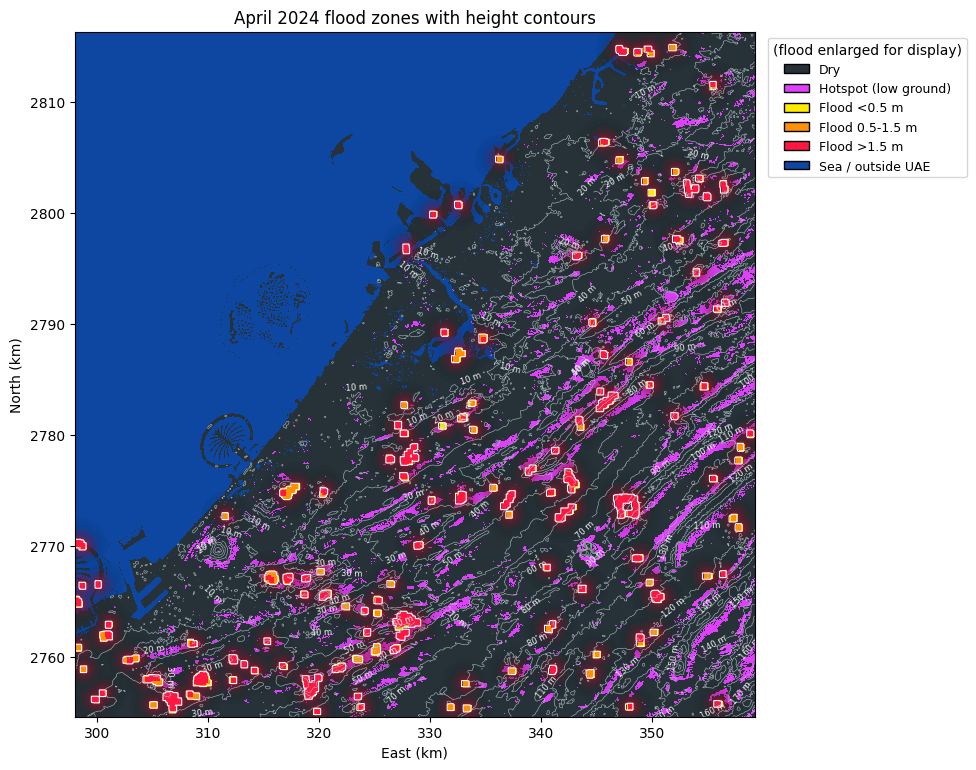

In [ ]:
import rasterio
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Patch

src = rasterio.open('stack.tif')
dem_a, depth_a, flood_a, hot_a = [src.read(i) for i in (1, 2, 3, 4)]
b, res = src.bounds, src.res[0]
h, w = dem_a.shape
ext = [b.left / 1000, b.right / 1000, b.bottom / 1000, b.top / 1000]  # km

# zone codes: 0 dry, 1 hotspot, 2 shallow, 3 medium, 4 deep, 5 sea
zone = np.zeros(dem_a.shape, int)
zone[dem_a <= 0.5] = 5
zone[hot_a > 0] = 1
fl = flood_a > 0
zone[fl] = 2 + (depth_a[fl] >= 0.5) + (depth_a[fl] >= 1.5)

fig, ax = plt.subplots(figsize=(9, 8))
draw_zone_map(ax, zone, ext, cmap)                 # dark background + glow + white outline

X = np.linspace(ext[0], ext[1], w)
Y = np.linspace(ext[3], ext[2], h)
smooth = gaussian_filter(dem_a, 1.5)
step = 5 if smooth.max() < 60 else 10            # metres between lines
levels = np.arange(step, min(smooth.max(), 200) + step, step)
cs = ax.contour(X, Y, smooth, levels=levels, colors='#B0BEC5', linewidths=0.4)
ax.clabel(cs, fmt='%d m', fontsize=6, colors='#ECEFF1')

ax.legend(handles=[Patch(fc=c, ec='k', label=l) for c, l in zip(ZONE_COLORS, ZONE_LABELS)],
          loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9,
          title='(flood enlarged for display)')
ax.set_xlabel('East (km)'); ax.set_ylabel('North (km)')
ax.set_title('April 2024 flood zones with height contours')
plt.tight_layout()
plt.savefig('fig_contour_zones.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 6 - 3D view (optional)
**CELL 10: 3D terrain view**

Renders a 3D terrain surface using the same colour code to illustrate the role of low-lying ground in flooding. The 2D map remains the basis for planning, as 3D views can obscure areas behind terrain and do not preserve distances. Output: fig_3d.png.

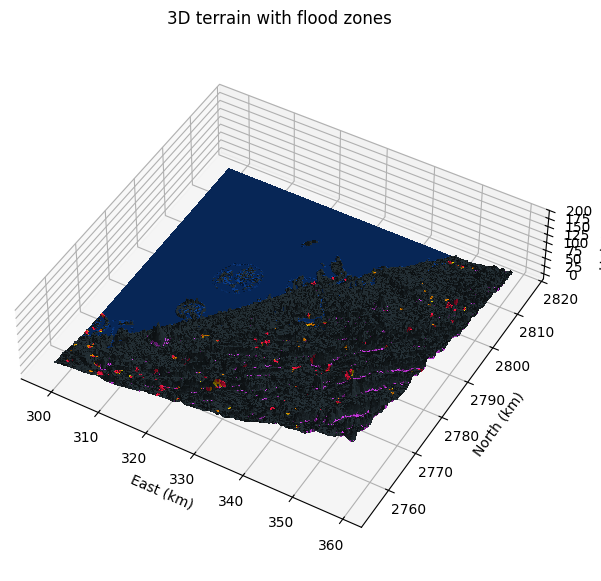

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # noqa

step = 6
Z = gaussian_filter(dem_a, 1)[::step, ::step]
from scipy.ndimage import grey_dilation
_fl = (zone >= 2) & (zone <= 4)
_big = grey_dilation(np.where(_fl, zone, 0), size=2 * step + 1)   # keep thin flood from vanishing when we subsample
_z = zone.copy(); _z[_big >= 2] = _big[_big >= 2]
F = _z[::step, ::step]
Xs, Ys = np.meshgrid(X[::step], Y[::step])

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(Xs, Ys, Z, facecolors=cmap(F), rstride=1, cstride=1,
                linewidth=0, antialiased=False)
ax.set_box_aspect((1, 1, 0.25))
ax.view_init(elev=45, azim=-60)
ax.set_xlabel('East (km)'); ax.set_ylabel('North (km)'); ax.set_zlabel('Height (m)')
ax.set_title('3D terrain with flood zones')
plt.savefig('fig_3d.png', dpi=150)
plt.show()

## Part 7 - Hospitals and schools at risk
**CELL 11: Retrieve hospitals, clinics and schools**

Retrieves the locations of hospitals, clinics and schools within the UAE from Overture Maps. Road data is excluded because of its download size and is noted as future work.

In [ ]:
!pip install -q overturemaps

In [ ]:
import os
import numpy as np, pandas as pd, geopandas as gpd
from shapely.geometry import shape
from overturemaps import core

def points_to_fc(df, lon='lon', lat='lat', props=(), chunk=2000):
    """DataFrame -> ee.FeatureCollection of points, sent in chunks to stay under request limits."""
    fcs = []
    for s in range(0, len(df), chunk):
        part = df.iloc[s:s + chunk]
        feats = [ee.Feature(ee.Geometry.Point([float(x), float(y)]),
                            {p: (None if pd.isna(v) else str(v))
                             for p, v in zip(props, vals)})
                 for x, y, *vals in part[[lon, lat, *props]].itertuples(index=False)]
        fcs.append(ee.FeatureCollection(feats))
    return ee.FeatureCollection(fcs).flatten()

CACHE = 'uae_facilities_overture.csv'
BUFFER_DEG = 0.02            # ~2 km tolerance so coastal/reclaimed-land places aren't cut off

# UAE border from Earth Engine
uae_shp = shape(uae.geometry().getInfo()).buffer(0)
uae_clip = uae_shp.buffer(BUFFER_DEG)

def get_cat(g):
    """Category text, whichever column this Overture release uses."""
    cat = pd.Series(None, index=g.index, dtype=object)
    for col in ('categories', 'taxonomy'):
        if col in g.columns:
            cat = cat.fillna(g[col].apply(lambda d: d.get('primary') if isinstance(d, dict) else None))
    if 'basic_category' in g.columns:
        cat = cat.fillna(g['basic_category'])
    return cat

BAD = ['veterinar', 'animal', 'pet_']
BAD_SCHOOL = ['driving', 'dance', 'art_', 'language', 'cooking', 'flight', 'music', 'sport',
              'martial', 'vocational', 'tutor', 'nursing', 'medical_school', 'law_school',
              'business_school', 'swimming', 'boxing', 'tennis', 'golf', 'drama', 'acting',
              'culinary', 'beauty', 'fashion', 'computer', 'coding', 'trade', 'technical',
              'cosmetology', 'massage', 'yoga']

def classify(c):
    if not isinstance(c, str):
        return None
    c = c.lower()
    if any(x in c for x in BAD):
        return None
    if 'hospital' in c:
        return 'hospital'
    if 'clinic' in c or 'medical_center' in c or 'urgent_care' in c:
        return 'clinic'
    if ('school' in c or 'kindergarten' in c) and not any(x in c for x in BAD_SCHOOL):
        return 'school'
    return None

if os.path.exists(CACHE):
    df0 = pd.read_csv(CACHE)
    print("Loaded", len(df0), "places from", CACHE)
else:
    # Download in 4 chunks to keep memory low
    minx, miny, maxx, maxy = uae_shp.bounds
    xs, ys = np.linspace(minx, maxx, 3), np.linspace(miny, maxy, 3)
    chunks = [(xs[i], ys[j], xs[i + 1], ys[j + 1]) for i in range(2) for j in range(2)]

    parts = []
    for k, bb in enumerate(chunks, 1):
        print(f"Chunk {k}/{len(chunks)} (can take a few minutes)...")
        g = core.geodataframe('place', bbox=bb)
        g['cat'] = get_cat(g)
        g['amenity'] = g['cat'].map(classify)
        g = g[g['amenity'].notna()].copy()
        if len(g) == 0:
            continue
        pts = g.geometry.where(g.geometry.geom_type == 'Point', g.geometry.representative_point())
        g['name'] = g['names'].apply(lambda d: d.get('primary') if isinstance(d, dict) else None) \
                    if 'names' in g.columns else None
        g['lon'], g['lat'] = pts.x, pts.y
        parts.append(g[['id', 'name', 'amenity', 'cat', 'lon', 'lat']])

    assert parts, "No places found. Check the internet connection and rerun."
    df0 = pd.concat(parts).drop_duplicates('id').drop(columns='id').reset_index(drop=True)
    df0.to_csv(CACHE, index=False)
    print("Saved", CACHE)

# Clip to the UAE border
fac_raw = gpd.GeoDataFrame(df0, geometry=gpd.points_from_xy(df0.lon, df0.lat), crs='EPSG:4326')
fac_raw = fac_raw[fac_raw.within(uae_clip)].reset_index(drop=True)
fac_raw['name'] = fac_raw['name'].fillna('unnamed')

print(len(fac_raw), "places downloaded inside the UAE border")
print(fac_raw['amenity'].value_counts())
print("\nOverture categories matched (check these look right):")
print(fac_raw['cat'].value_counts().head(15))

# ---------- Map ----------
colors = {'hospital': 'FF1744', 'clinic': 'FF9100', 'school': '00E5FF'}
m = geemap.Map()
m.add_basemap("HYBRID")
dim_basemap(m)
m.setCenter(55.3, 25.2, 9)
m.addLayer(uae.style(color='white', fillColor='00000000', width=1), {}, 'UAE border')
fac_ee = points_to_fc(fac_raw, props=['name', 'amenity'])
for a, col in colors.items():
    m.addLayer(bold_points(fac_ee.filter(ee.Filter.eq('amenity', a)), col, 6), {}, a.capitalize())
m

Chunk 1/4 (can take a few minutes)...
Chunk 2/4 (can take a few minutes)...
Chunk 3/4 (can take a few minutes)...
Chunk 4/4 (can take a few minutes)...
Saved uae_facilities_overture.csv
4065 places downloaded inside the UAE border
amenity
school      1908
hospital    1330
clinic       827
Name: count, dtype: int64

Overture categories matched (check these look right):
cat
hospital                     1324
school                        701
dental_clinic                 701
preschool                     439
private_school                327
day_care_preschool            133
elementary_school             103
high_school                    94
specialty_school               67
vision_or_eye_care_clinic      44
pediatric_clinic               31
fertility_clinic               24
middle_school                  22
public_health_clinic           11
religious_school               10
Name: count, dtype: int64


Map(center=[25.2, 55.3], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

**CELL 12: Identify facilities inside the flood zones**

Looks up each facility on the zone map and classifies it as dry, hotspot (at risk) or flooded. Flooded hospitals and schools are marked with black crosses as priorities for response. Output: fig_facilities.png.

Pixels outside the UAE border set to 'none': 36%
status
dry                  2358
sea/none              105
hotspot (at risk)      36
flood <0.5 m            1
Name: count, dtype: int64

FLOODED PLACES:
                          name amenity       status
Dubai Sky Clinic Dental Center  clinic flood <0.5 m


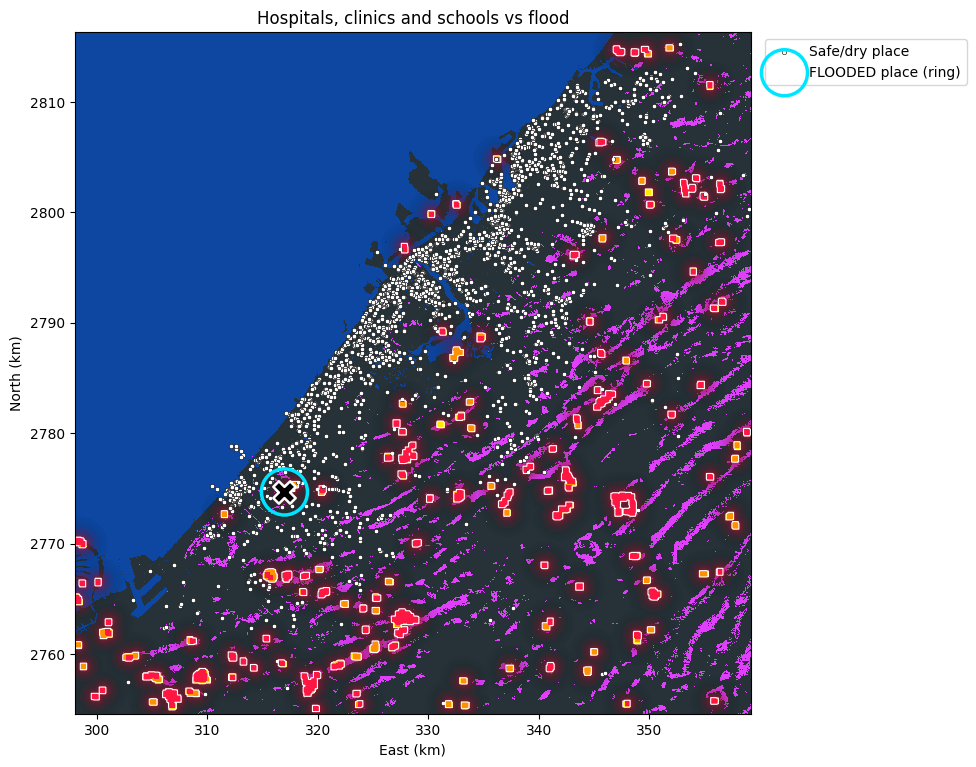

Map(center=[25.076736815647028, 55.185479521751404], controls=(WidgetControl(options=['position', 'transparent…

In [ ]:
import rasterio, rasterio.features, rasterio.transform
import matplotlib.pyplot as plt, seaborn as sns

# ---------- Helper: DataFrame -> Earth Engine points (no df_to_ee needed) ----------
def points_to_fc(df, lon='lon', lat='lat', props=(), chunk=2000):
    fcs = []
    for s in range(0, len(df), chunk):
        part = df.iloc[s:s + chunk]
        feats = [ee.Feature(ee.Geometry.Point([float(x), float(y)]),
                            {p: (None if pd.isna(v) else str(v))
                             for p, v in zip(props, vals)})
                 for x, y, *vals in part[[lon, lat, *props]].itertuples(index=False)]
        fcs.append(ee.FeatureCollection(feats))
    return ee.FeatureCollection(fcs).flatten()

needed = ['zone', 'dem_a', 'src', 'h', 'w', 'res', 'b', 'ext', 'cmap', 'fac_raw', 'uae_shp']
missing = [n for n in needed if n not in globals()]
assert not missing, f"Run the earlier cells first. Missing: {missing}"

# 1. Border clip on the zone map: everything outside the UAE becomes 5 (sea/none),
#    so dry ground in Oman, Saudi Arabia or Iran can't be picked as a staging point
uae_utm = gpd.GeoSeries([uae_shp], crs='EPSG:4326').to_crs(src.crs).iloc[0]
inside = rasterio.features.rasterize([(uae_utm, 1)], out_shape=(h, w),
                                     transform=src.transform, fill=0, dtype='uint8').astype(bool)
print(f"Pixels outside the UAE border set to 'none': {100 * (~inside).mean():.0f}%")
zone[~inside] = 5

# 2. Facilities -> pixel row/col
fac = fac_raw.to_crs(src.crs).reset_index(drop=True)
fac['x'], fac['y'] = fac.geometry.x, fac.geometry.y

r_, c_ = rasterio.transform.rowcol(src.transform, fac['x'].values, fac['y'].values)
fac['row'], fac['col'] = np.array(r_), np.array(c_)
fac = fac[(fac.row >= 0) & (fac.row < h) & (fac.col >= 0) & (fac.col < w)]
fac = fac.copy().reset_index(drop=True)
fac['zone'] = zone[fac['row'].values, fac['col'].values]

names = {0: 'dry', 1: 'hotspot (at risk)', 2: 'flood <0.5 m',
         3: 'flood 0.5-1.5 m', 4: 'flood >1.5 m', 5: 'sea/none'}
fac['status'] = fac['zone'].map(names)
print(fac['status'].value_counts())

hit = fac[fac['zone'].between(2, 4)]
safe = fac[~fac['zone'].between(2, 4)]
print("\nFLOODED PLACES:")
print(hit[['name', 'amenity', 'status']].to_string(index=False))

# 3. Static figure
fig, ax = plt.subplots(figsize=(9, 8))
draw_zone_map(ax, zone, ext, cmap)
ax.scatter(safe.x / 1000, safe.y / 1000, s=10, c='white', edgecolors='k',
           linewidths=0.4, label='Safe/dry place')
if len(hit):
    ax.scatter(hit.x / 1000, hit.y / 1000, s=1100, facecolors='none', edgecolors='#00E5FF',
               linewidths=2.5, label='FLOODED place (ring)')              # big ring = easy to spot
    ax.scatter(hit.x / 1000, hit.y / 1000, s=260, c='black', marker='X',
               edgecolors='white', linewidths=1.8, zorder=5)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_xlabel('East (km)'); ax.set_ylabel('North (km)')
ax.set_title('Hospitals, clinics and schools vs flood')
plt.tight_layout()
plt.savefig('fig_facilities.png', dpi=150, bbox_inches='tight')
plt.show()

# 4. Interactive HYBRID map
m = geemap.Map()
m.add_basemap("HYBRID")
dim_basemap(m)
if len(hit):
    m.setCenter(float(hit.lon.iloc[0]), float(hit.lat.iloc[0]), 11)
else:
    m.setCenter(55.3, 25.2, 8)
m.addLayer(uae.style(color='white', fillColor='00000000', width=1), {}, 'UAE border')
m.addLayer(glow_image(flood, 'FF1744'), {}, 'Flood (glow, enlarged)')
if len(safe):
    s_ = safe.sample(min(len(safe), 3000), random_state=1)      # display only
    m.addLayer(points_to_fc(s_, props=['name', 'amenity'])
               .style(color='white', pointSize=3), {}, 'Safe places')
if len(hit):
    m.addLayer(bold_points(points_to_fc(hit, props=['name', 'amenity']), 'FFEB3B', 14), {}, 'FLOODED places')
m

## Part 8 - Priority table and action plan
**CELL 13: Rank sectors for response**

Divides the study area into an N x N grid of sectors (N = 8). Each sector is scored as: flood km2 + 3 x deep + 1.5 x medium + 0.5 x hotspot + 0.5 x flooded places. The weights are a design choice and can be adjusted. Sectors are ranked and assigned a tier: Critical, High, Moderate or Low. For each sector, a staging point is proposed at the closest dry ground more than 2 m above the flood water, and the lead team is NDRF if deep water exceeds 30% of the flooded area, otherwise SDRF. Output: priority table, heatmap and bar chart (fig_priority.png).

 rank sector     tier              lead_team  flood_km2  deep_km2  places_flooded  stage_lat  stage_lon
    1   R8C4 Critical   NDRF (boats, divers)       0.30      0.10               0      24.95      55.26
    2   R4C7 Critical   NDRF (boats, divers)       0.06      0.02               0      25.21      55.49
    3   R5C8 Critical SDRF (boats, vehicles)       0.06      0.01               0      25.14      55.57
    4   R8C8 Critical   NDRF (boats, divers)       0.01      0.00               0      24.91      55.57
    5   R7C3 Critical SDRF (boats, vehicles)       0.38      0.09               0      25.01      55.19
    6   R7C5 Critical   NDRF (boats, divers)       0.02      0.02               0      25.00      55.31
    7   R4C8 Critical   NDRF (boats, divers)       0.03      0.02               0      25.23      55.57
    8   R5C6 Critical   NDRF (boats, divers)       0.04      0.02               0      25.13      55.44
    9   R3C8 Critical   NDRF (boats, divers)       0.05      0.0

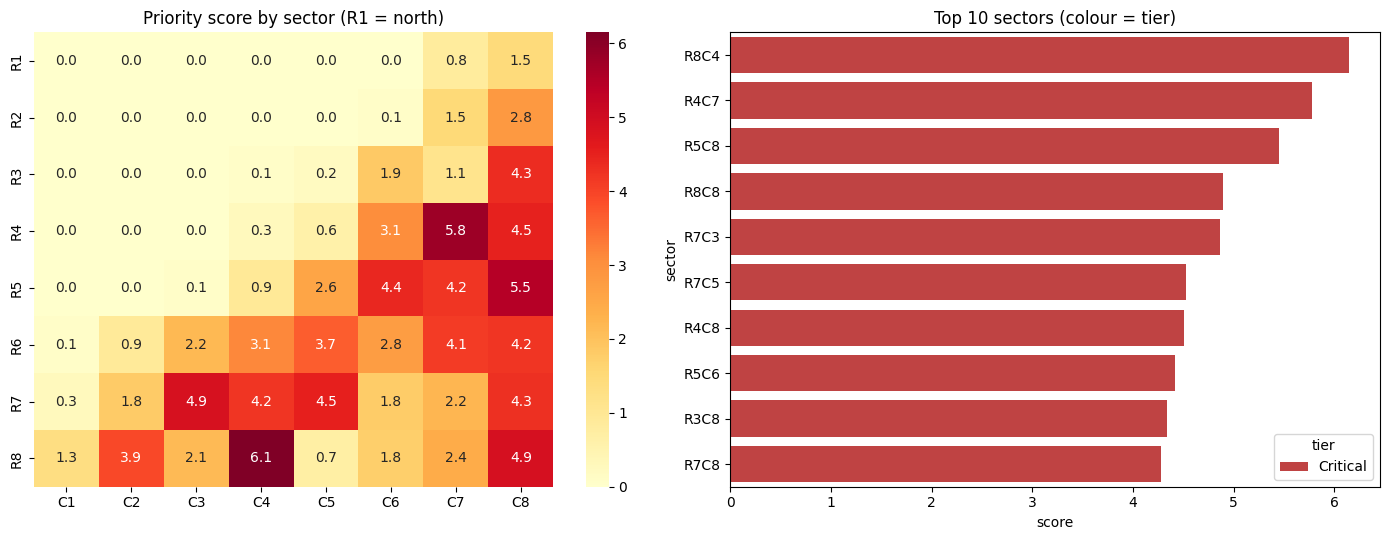

Map(center=[25.2, 55.3], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

In [ ]:
from pyproj import Transformer

# Helper (same as Cell 12; harmless if defined twice)
def points_to_fc(df, lon='lon', lat='lat', props=(), chunk=2000):
    fcs = []
    for s in range(0, len(df), chunk):
        part = df.iloc[s:s + chunk]
        feats = [ee.Feature(ee.Geometry.Point([float(x), float(y)]),
                            {p: (None if pd.isna(v) else str(v))
                             for p, v in zip(props, vals)})
                 for x, y, *vals in part[[lon, lat, *props]].itertuples(index=False)]
        fcs.append(ee.FeatureCollection(feats))
    return ee.FeatureCollection(fcs).flatten()

to_ll = Transformer.from_crs(src.crs, 4326, always_xy=True)

N = 8                                   # N x N sectors (8 suits a country-wide map; use 5 for a small area)
px_km2 = (res * res) / 1e6
row_groups = np.array_split(np.arange(h), N)
col_groups = np.array_split(np.arange(w), N)

def staging(r, c):
    """Closest dry ground >2 m above flood ground, near the flood centre."""
    z = zone[np.ix_(r, c)]; d = dem_a[np.ix_(r, c)]
    flooded = (z >= 2) & (z <= 4)
    if flooded.sum() == 0:
        return (np.nan, np.nan)
    ok = (z == 0) & (d > np.median(d[flooded]) + 2)
    if ok.sum() == 0:
        return (np.nan, np.nan)
    cy, cx = np.argwhere(flooded).mean(0)
    ys, xs = np.nonzero(ok)
    k = np.argmin((ys - cy) ** 2 + (xs - cx) ** 2)
    X0 = b.left + (c[0] + xs[k] + 0.5) * res
    Y0 = b.top - (r[0] + ys[k] + 0.5) * res
    lon, lat = to_ll.transform(X0, Y0)
    return (round(lat, 4), round(lon, 4))

recs = []
for i, r in enumerate(row_groups):
    for j, c in enumerate(col_groups):
        z = zone[np.ix_(r, c)]
        n_hit = ((fac.row.isin(r)) & (fac.col.isin(c)) & fac.zone.between(2, 4)).sum()
        lat, lon = staging(r, c)
        recs.append(dict(sector=f"R{i+1}C{j+1}", i=i, j=j,
                         flood_km2=((z >= 2) & (z <= 4)).sum() * px_km2,
                         deep_km2=(z == 4).sum() * px_km2,
                         medium_km2=(z == 3).sum() * px_km2,
                         hotspot_km2=(z == 1).sum() * px_km2,
                         places_flooded=int(n_hit),
                         stage_lat=lat, stage_lon=lon))
df_all = pd.DataFrame(recs)
df_all['score'] = (df_all.flood_km2 + 3 * df_all.deep_km2
                   + 1.5 * df_all.medium_km2 + 0.5 * df_all.hotspot_km2
                   + 0.5 * df_all.places_flooded)

df = df_all[df_all.score > 0].sort_values('score', ascending=False).reset_index(drop=True)
assert len(df) > 0, "No sector has any flood. Check the flood map and dates first."
df['rank'] = df.index + 1

# Tiers by position (works even with fewer than 4 sectors)
tier_names = np.array(['Critical', 'High', 'Moderate', 'Low'])
df['tier'] = tier_names[np.minimum(df.index.values * 4 // len(df), 3)]
df['lead_team'] = np.where(df.deep_km2 > 0.3 * df.flood_km2,
                           'NDRF (boats, divers)', 'SDRF (boats, vehicles)')

cols = ['rank', 'sector', 'tier', 'lead_team', 'flood_km2', 'deep_km2',
        'places_flooded', 'stage_lat', 'stage_lon']
print(df[cols].round(2).to_string(index=False))

# Charts
pal = {'Critical': '#D32F2F', 'High': '#FB8C00', 'Moderate': '#FFD54F', 'Low': '#66BB6A'}
grid = np.zeros((N, N))
for _, rr in df_all.iterrows():
    grid[int(rr.i), int(rr.j)] = rr.score

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(grid, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax[0],
            xticklabels=[f"C{k+1}" for k in range(N)],
            yticklabels=[f"R{k+1}" for k in range(N)])
ax[0].set_title('Priority score by sector (R1 = north)')
top = df.head(10)
sns.barplot(data=top, y='sector', x='score', hue='tier', palette=pal,
            dodge=False, ax=ax[1])
ax[1].set_title('Top 10 sectors (colour = tier)')
plt.tight_layout()
plt.savefig('fig_priority.png', dpi=150)
plt.show()

# Interactive HYBRID map: staging points coloured by tier
stg = df.dropna(subset=['stage_lat', 'stage_lon'])
m = geemap.Map()
m.add_basemap("HYBRID")
dim_basemap(m)
m.setCenter(55.3, 25.2, 8)
m.addLayer(uae.style(color='white', fillColor='00000000', width=1), {}, 'UAE border')
m.addLayer(glow_image(flood, 'FF1744'), {}, 'Flood (glow, enlarged)')
if len(stg):
    stg_ee = points_to_fc(stg, lon='stage_lon', lat='stage_lat',
                          props=['sector', 'tier', 'lead_team', 'rank'])
    for t in tier_names:
        m.addLayer(bold_points(stg_ee.filter(ee.Filter.eq('tier', t)), pal[t].lstrip('#'), 12),
                   {}, f'Staging: {t}')
m